# Print sizes and units

You will build: an A6 postcard measured in millimetres, ready to print at 300 dpi.

Run it from this folder with ``python print_sizes.py``, or open ``print_sizes.ipynb``.

In [1]:
import svgwriter as svg

`size="a6-landscape"` makes a 148 x 105 mm page, and plain numbers on it count in millimetres.

viewBox: ViewBox(min_x=0, min_y=0, width=148.0, height=105.0) | width: 148mm


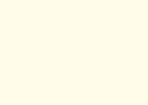

In [2]:
card = svg.Document(size="a6-landscape")
width, height = (side.value for side in svg.page_size("a6-landscape"))
card.rect(0, 0, width, height, fill="#fefce8")
print("viewBox:", card.root.get("viewBox"), "| width:", card.root.get("width"))
card

Other units convert to millimetres: a quarter-inch margin and a 1-point border line.

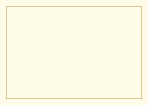

In [3]:
margin = svg.inch(0.25).to("mm").value
card.rect(margin, margin, width - 2 * margin, height - 2 * margin, fill="none", stroke="#a16207",
          stroke_width=svg.pt(1).to("mm").value)
card

Font sizes work the same way: an 18-point title.

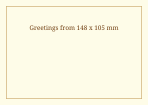

In [4]:
card.text("Greetings from 148 x 105 mm", x=width / 2, y=30, font_size=svg.pt(18).to("mm").value,
          font_family="Georgia, serif", text_anchor="middle", fill="#713f12")
card

Angles take degrees (`svg.deg`) or turns (`svg.turn`): eight rays, each an eighth of a turn apart.

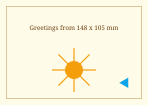

In [5]:
for index in range(8):
    ray = svg.rect(width / 2 - 0.6, 48, 1.2, 22, fill="#f59e0b")
    card += ray.rotate(svg.turn(index / 8), about=(width / 2, 70))
card.circle(width / 2, 70, 9, fill="#f59e0b")
card += svg.Polygon.regular(width - 22, height - 22, 6, 3, fill="#0ea5e9").rotate(svg.deg(30))
card

`dpi=300` saves the real size at print quality. Rarer units live in `svg.units` (such as `svg.units.km`).
Next: [13 Math and diagrams](../13_math_and_diagrams/math_and_diagrams.py).

In [6]:
card.save("12_postcard.svg")
card.save("12_postcard.png", dpi=300)
print("12_postcard.png is", svg.Document.open("12_postcard.png").root.get("width"), "px wide")

12_postcard.png is 1750 px wide
